# 01 - Data Discovery
NeuroVision AI Part 3: explore the *MRI for Brain Tumor with Bounding Boxes* dataset.

**Goals**
1. Inspect the folder structure and file types
2. Read an annotation (`class xc yc w h`, normalized 0-1)
3. Display at least 9 images with boxes and class names (converted back to pixels)
4. Plot the class distribution (images and boxes) and spot imbalance

In [3]:
import sys, random
from pathlib import Path
from collections import Counter

import cv2
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../src")
from neurovision.config import SEED, set_seed

set_seed(SEED)

ROOT = Path("../data/raw_bbox")
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
print("Root exists:", ROOT.exists())

Root exists: True


## 1. Folder structure and file types

In [4]:
# Sub-folders (2 levels deep)
for d in sorted(p for p in ROOT.rglob("*") if p.is_dir() and len(p.relative_to(ROOT).parts) <= 2):
    print(d.relative_to(ROOT))

# File count per extension
ext_counts = Counter(p.suffix.lower() for p in ROOT.rglob("*") if p.is_file())
print()
print(ext_counts)

Train
Train/Glioma
Train/Meningioma
Train/No Tumor
Train/Pituitary
Val
Val/Glioma
Val/Meningioma
Val/No Tumor
Val/Pituitary

Counter({'.jpg': 5249, '.txt': 5249})


**Notes to fill in:** folder layout (Train / Valid / Test, images and labels together or separated), annotation format (YOLO `.txt` expected), other files (yaml, csv...).

## 2. Class names and one annotation

In [5]:
# Look for a yaml file that may contain the class names
yamls = list(ROOT.rglob("*.yaml")) + list(ROOT.rglob("*.yml"))
print("YAML files:", yamls)
if yamls:
    print(yamls[0].read_text())

YAML files: []


In [6]:
# Fill in the real class names (from the yaml above or from the Kaggle page)
CLASS_NAMES = ["class0", "class1"]

txts = [p for p in ROOT.rglob("*.txt") if p.stat().st_size > 0]
example = txts[0]
print(example)
print(example.read_text())

../data/raw_bbox/Val/Pituitary/labels/Te-pi_0018.txt
3 0.496094 0.408203 0.062500 0.066406



Each line is `class x_center y_center width height`, all normalized between 0 and 1.
To get pixels: multiply `x_center` and `width` by the image width, `y_center` and `height` by the image height, then `x1 = xc - w/2`, `y1 = yc - h/2`.

## 3. Display 9 images with their boxes

Total images: 5249


IndexError: list index out of range

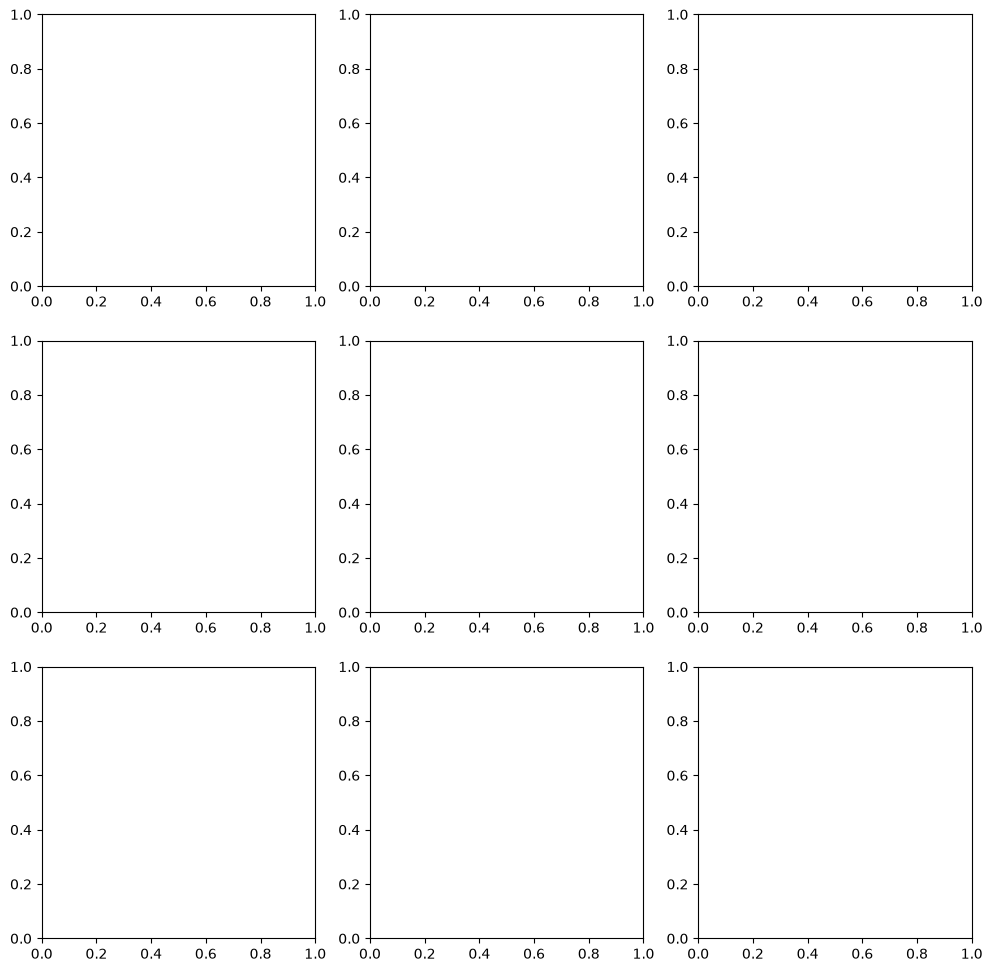

In [7]:
def find_label(img_path: Path):
    """Label next to the image, or in a parallel labels/ folder."""
    same_dir = img_path.with_suffix(".txt")
    if same_dir.exists():
        return same_dir
    parallel = Path(str(img_path).replace("images", "labels")).with_suffix(".txt")
    return parallel if parallel.exists() else None


def draw_boxes(img_path: Path):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    label_path = find_label(img_path)
    if label_path is not None:
        for line in label_path.read_text().splitlines():
            if not line.strip():
                continue
            c, xc, yc, bw, bh = line.split()
            xc, bw = float(xc) * w, float(bw) * w
            yc, bh = float(yc) * h, float(bh) * h
            x1, y1 = int(xc - bw / 2), int(yc - bh / 2)
            x2, y2 = int(xc + bw / 2), int(yc + bh / 2)
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
            cv2.putText(img, CLASS_NAMES[int(c)], (x1, max(y1 - 5, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    return img


images = sorted(p for p in ROOT.rglob("*") if p.suffix.lower() in IMG_EXT)
print("Total images:", len(images))

sample = random.sample(images, 9)
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, p in zip(axes.ravel(), sample):
    ax.imshow(draw_boxes(p))
    ax.set_title(p.name, fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig("sample_boxes.png", dpi=120)
plt.show()

In [8]:
ids = Counter()
for p in ROOT.rglob("*.txt"):
    for line in p.read_text().splitlines():
        if line.strip():
            ids[int(line.split()[0])] += 1
print(sorted(ids.items()))

[(0, 1502), (1, 1624), (2, 811), (3, 1936)]


In [9]:
for y in list(ROOT.rglob("*.yaml")) + list(ROOT.rglob("*.yml")) + list(ROOT.rglob("classes.txt")):
    print(y)
    print(y.read_text())

In [11]:
CLASS_NAMES = ["class_0", "class_1", "class_2", "class_3"]

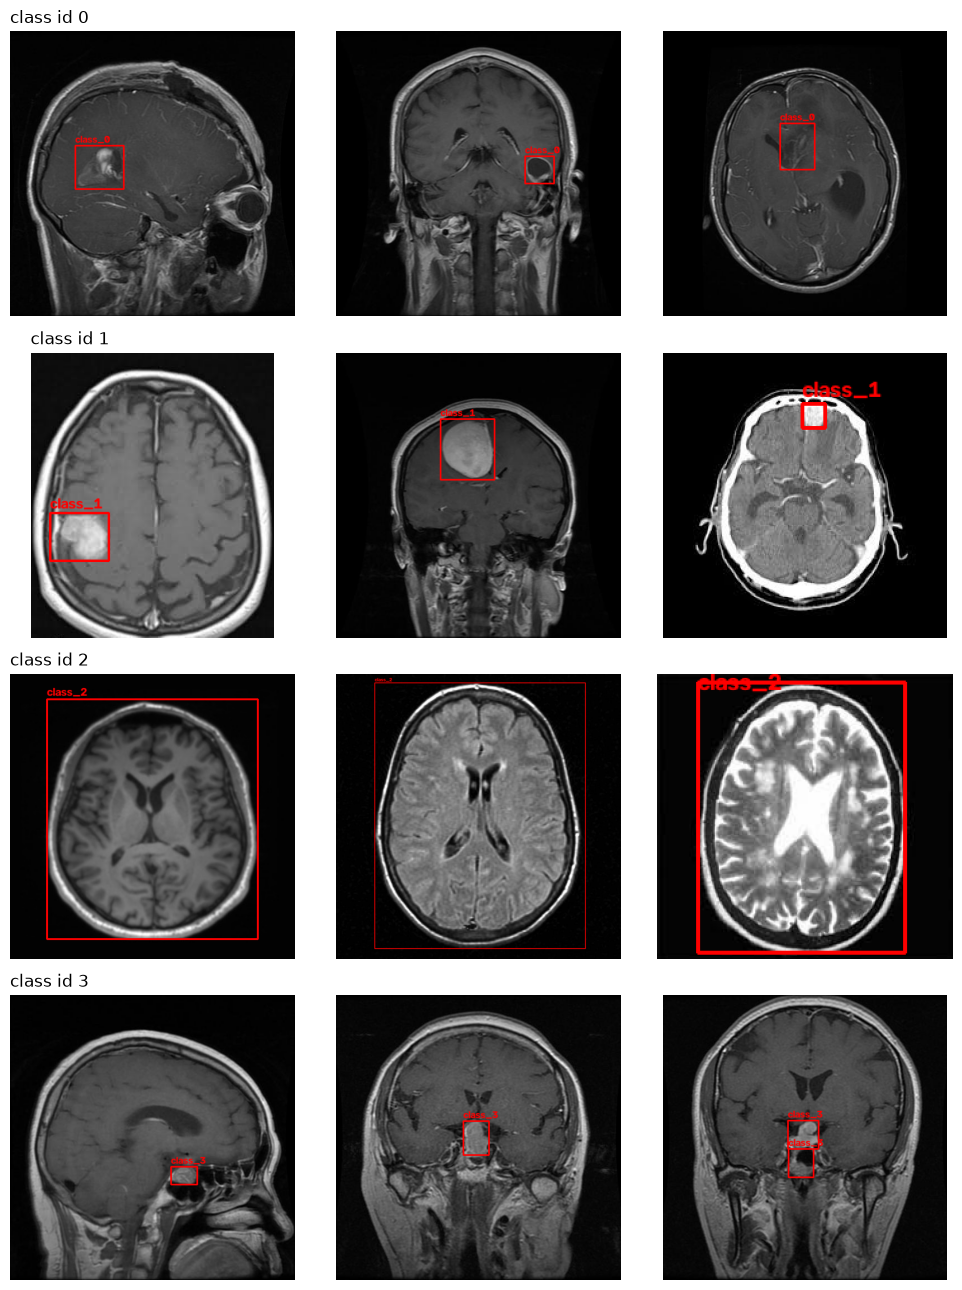

In [12]:
by_class = {i: [] for i in range(4)}
for img in images:
    label = find_label(img)
    if label is None:
        continue
    ids = {int(l.split()[0]) for l in label.read_text().splitlines() if l.strip()}
    if len(ids) == 1:                      # images with a single class only
        by_class[ids.pop()].append(img)

fig, axes = plt.subplots(4, 3, figsize=(10, 13))
for cid, row in zip(range(4), axes):
    for ax, p in zip(row, random.sample(by_class[cid], 3)):
        ax.imshow(draw_boxes(p)); ax.axis("off")
    row[0].set_title(f"class id {cid}", loc="left")
plt.tight_layout(); plt.show()

In [15]:
from collections import Counter

folder_to_ids = {}
for class_dir in sorted((ROOT / "Train").iterdir()):
    if not class_dir.is_dir():
        continue
    ids = Counter()
    n_imgs = 0
    for img in class_dir.rglob("*"):
        if img.suffix.lower() in IMG_EXT:
            n_imgs += 1
            label = find_label(img)
            if label is not None:
                for line in label.read_text().splitlines():
                    if line.strip():
                        ids[int(line.split()[0])] += 1
    folder_to_ids[class_dir.name] = dict(ids)
    print(f"{class_dir.name:12s} images={n_imgs:5d}  class ids in labels={dict(ids)}")

Glioma       images= 1153  class ids in labels={0: 1347, 3: 152, 1: 3}
Meningioma   images= 1449  class ids in labels={1: 1478, 0: 2, 3: 103}
No Tumor     images=  711  class ids in labels={2: 711}
Pituitary    images= 1424  class ids in labels={3: 1520, 1: 1}


## 4. Class distribution (images and boxes) per split

In [13]:
rows = []
for img in images:
    split = img.relative_to(ROOT).parts[0]   # Train / Valid / Test (adapt if needed)
    label = find_label(img)
    classes = []
    if label is not None:
        classes = [int(l.split()[0]) for l in label.read_text().splitlines() if l.strip()]
    rows.append({"split": split, "image": img.name, "has_label": label is not None,
                 "n_boxes": len(classes), "classes": classes})

df = pd.DataFrame(rows)
print("Images without label file:", (~df.has_label).sum())
print("Images with empty annotation (no tumor?):", ((df.has_label) & (df.n_boxes == 0)).sum())
df.groupby("split").size()

Images without label file: 2
Images with empty annotation (no tumor?): 1


split
Train    4737
Val       512
dtype: int64

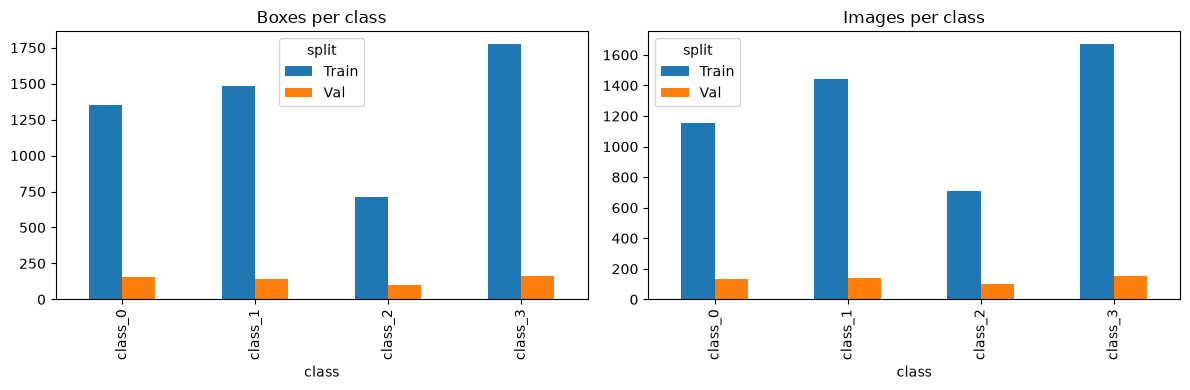

split,Train,Val,All
class,,,
class_0,1349,153,1502
class_1,1482,142,1624
class_2,711,98,809
class_3,1775,161,1936
All,5317,554,5871


In [14]:
# Boxes and images per class, per split
box_rows = [{"split": r.split, "class": CLASS_NAMES[c]} for r in df.itertuples() for c in r.classes]
boxes = pd.DataFrame(box_rows)

img_rows = [{"split": r.split, "class": CLASS_NAMES[c]}
            for r in df.itertuples() for c in set(r.classes)]
imgs = pd.DataFrame(img_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.crosstab(boxes["class"], boxes["split"]).plot.bar(ax=axes[0], title="Boxes per class")
pd.crosstab(imgs["class"], imgs["split"]).plot.bar(ax=axes[1], title="Images per class")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=120)
plt.show()

pd.crosstab(boxes["class"], boxes["split"], margins=True)

## Findings (fill in)
- Folder structure:
- Annotation format:
- Class names:
- Images per split:
- Class imbalance:
- Images without label file / with empty annotation:
- Multiple boxes per image?:

These notes feed the next story: **cleaning** (pairing, extensions, corrupted images, annotation validation).